# Orientation, phase and strain mapping of a two-phase titanium alloy

Detect the Bragg disks, center and calibrate the patterns, then match both phases, refine their orientations, decide the phase at every position, and measure the projected strain.

Data from I. MacLaren *et al.*, [*J. Microscopy* **295**, 131 (2024)](https://doi.org/10.1111/jmi.13275): hcp alpha titanium laths in a bcc beta matrix, 200 kV, 0.5 degree precession.

Colin Ophus  
Last updated: October 18, 2026

In [1]:
import urllib.request
from pathlib import Path

import numpy as np
import torch
from ase.build import bulk

import quantem as em
from quantem.core.io.file_readers import read_emdfile_to_4dstem
from quantem.core.visualization import show_2d
from quantem.diffraction import BraggVectors, Crystal, CrystalMap

print(em.__version__)

0.1.10


# Data

The first run downloads [Ti550_005_downsampled.h5](https://drive.google.com/file/d/1ASIrVm4DOr_S_UkTq-t-a8xKZVK3Y4qx/view) (313 MB) into `data/`.

In [2]:
file_data = Path('../../data/Ti550_005_downsampled.h5')
url_data = 'https://drive.usercontent.google.com/download?id=1ASIrVm4DOr_S_UkTq-t-a8xKZVK3Y4qx&export=download&confirm=t'
if not file_data.exists():
    urllib.request.urlretrieve(url_data, file_data.with_suffix('.part'))
    file_data.with_suffix('.part').rename(file_data)
dataset = read_emdfile_to_4dstem(file_data)

energy_ev = 200e3
precession_deg = 0.5
device = 'mps' if torch.backends.mps.is_available() else 'cpu'   # correlation matching device
pixel_size_guess = 0.038       # 1/Angstrom per pixel, calibrated below
scan_step = 30.0               # Angstroms per probe step
rotation_ccw_deg = 34.0        # diffraction-to-scan rotation, MacLaren et al. (2024)

# the scan calibration travels with the data: the detected peaks carry it and
# every map draws its scale bar from it
dataset.sampling = [scan_step, scan_step, 1.0, 1.0]
dataset.units = ['A', 'A', 'pixels', 'pixels']

# probe positions used to check every stage before running the scan:
# two alpha laths, the beta matrix, and a grain boundary
test_positions = [(50, 130), (26, 76), (30, 121), (80, 40)]
print(dataset.shape)

keys:  ['datacube_root', 'datacube', 'data']
(100, 191, 64, 64)


(<Figure size 800x400 with 2 Axes>,
 array([<Axes: title={'center': 'mean pattern'}>,
        <Axes: title={'center': 'max pattern'}>], dtype=object))

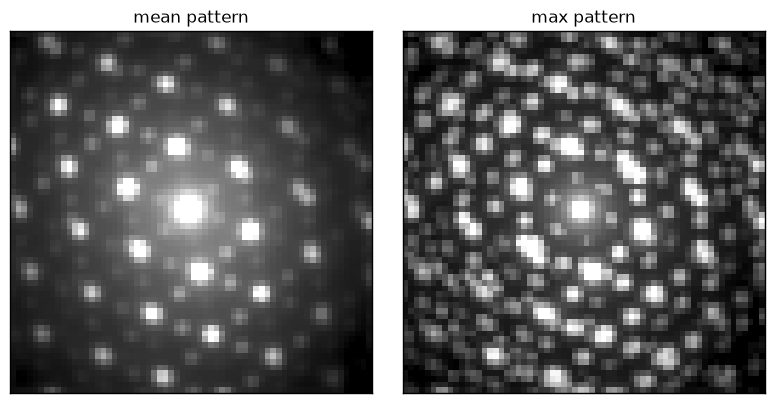

In [3]:
dataset.get_dp_mean(attach=True)
dataset.get_dp_max(attach=True)
show_2d(
    [dataset.dp_mean.array, dataset.dp_max.array],
    title=['mean pattern', 'max pattern'],
    norm={'power': 0.5},
)

# Bragg disk detection

No vacuum probe was recorded, so the template is a synthetic disk matching the direct beam. `background_sigma` is a Fourier high-pass on the cross-correlation, set somewhat wider than a disk.

In [4]:
detect_params = dict(
    min_abs_intensity=40.0,
    min_spacing=4.0,
    edge_boundary=2.0,
    background_sigma=1.0,      # high-pass width in pixels, wider than a disk
    subpixel='upsample',
    upsample_factor=16,
    max_num_peaks=500,
)

bv = BraggVectors.from_dataset(dataset)
bv.make_template_synthetic(
    radius=0.75,
    edge=1.0,
)

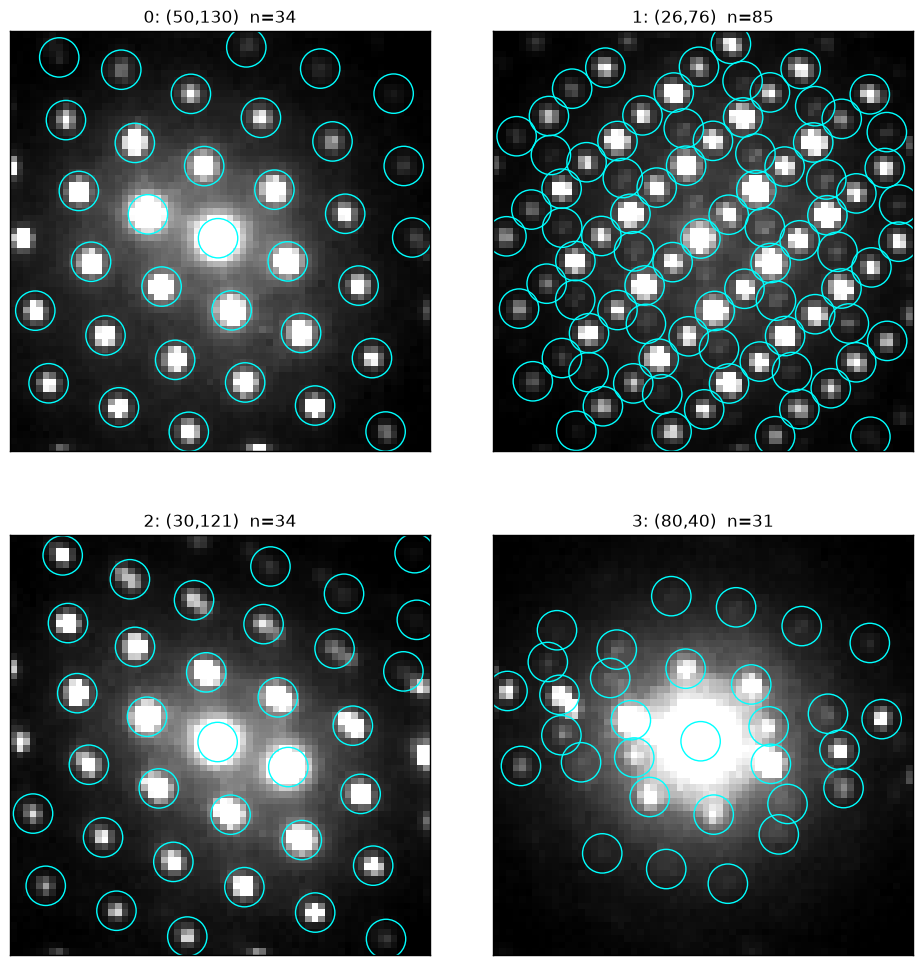

In [5]:
bv.show_detection(
    positions=test_positions,
    **detect_params,
    peak_radius=3,
    ncols=2,
    axsize=(6, 6),
    norm={
        'power': 1.0,
        'upper_quantile': 0.95,
    },
)

In [6]:
peaks_px = bv.detect_disks(**detect_params)

detect_disks:   0%|          | 0/19100 [00:00<?, ?it/s]

# Centering

The origin at each position is the brightest peak near the detector center; a plane fit over the scan models the descan.

In [7]:
origins = bv.measure_origins(search_radius=6.0)
bv_centered = bv.correct_peak_origins(origins, origin_ref=(0.0, 0.0))

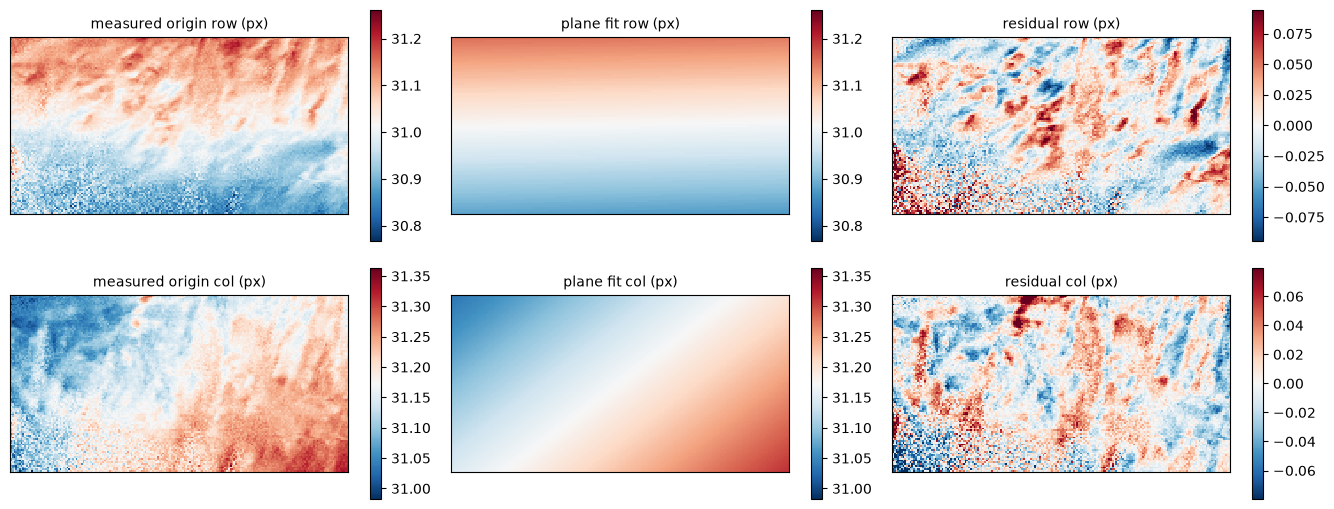

In [8]:
fig, axs = bv.plot_origin_fit(origins, search_radius=6.0)

# Candidate structures

Both phases from ASE. `Crystal` prints the symmetry it will use for matching, including any pseudo-symmetry found within `pseudo_symmetry_tol`. The structure factors set the k_max of every simulation below.

In [9]:
ti_alpha = Crystal.from_ase(
    bulk('Ti', 'hcp', a=2.9505, c=4.6855),
    name='Ti alpha',
    pseudo_symmetry_tol=0.01,        # fraction of the shortest lattice vector
).calculate_structure_factors(k_max=1.5)

ti_beta = Crystal.from_ase(
    bulk('Ti', 'bcc', a=3.26, cubic=True),
    name='Ti beta',
    pseudo_symmetry_tol=0.01,
).calculate_structure_factors(k_max=1.5)

Ti alpha
  space group      P6₃/mmc (194)
  point group      6/mmm   (Laue class 6/mmm)
  pseudo-symmetry  none found at tol = 0.01 (0.030 A)
  matching         12 proper rotations, zone axis wedge [0001], [101̅0], [21̅1̅0]
Ti beta
  space group      Im-3m (229)
  point group      m-3m   (Laue class m-3m)
  pseudo-symmetry  none found at tol = 0.01 (0.033 A)
  matching         24 proper rotations, zone axis wedge [001], [011], [111]


# Calibration

The beta matrix is one grain, so the sum of every pattern is a single beta zone axis. `calibrate_2d` indexes that summed pattern and fits the pixel size and the elliptic distortion to its spots as a 2D distortion. Top: the rings. Bottom: the 2D histogram of every peak in red, under the simulated spots in black.

DiffractionCalibration(pixel_size=0.038418 1/A/px, ellipse: e11 +0.00385 e12 +0.00483, rotation 34 deg, Ti beta, 27 spots, rms 0.0025 1/A)


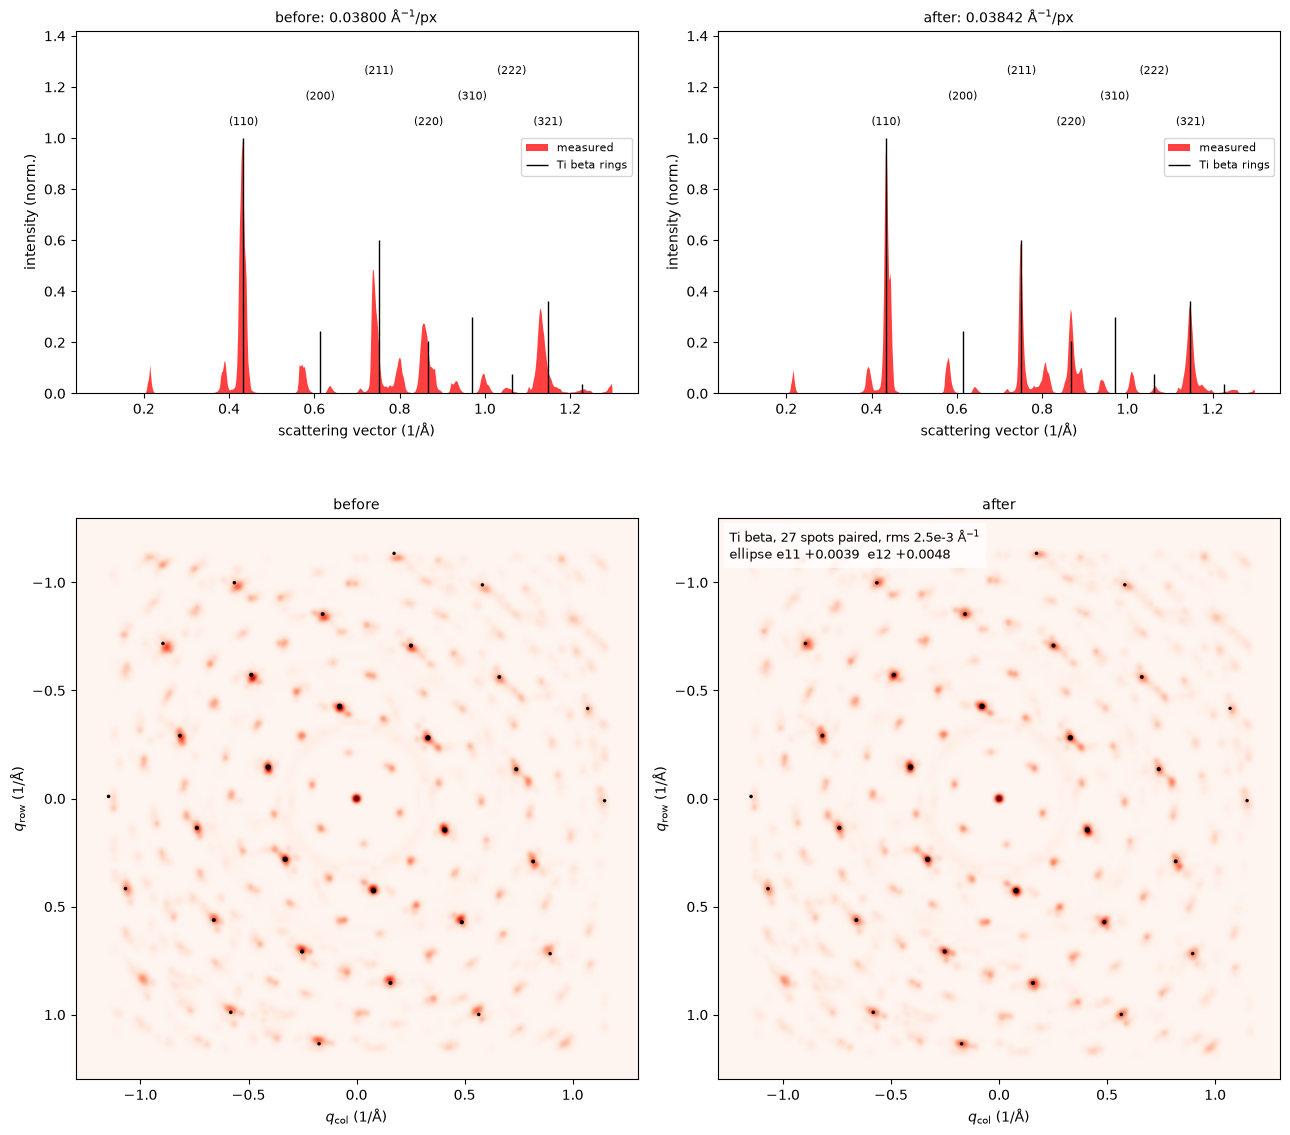

In [10]:
cal = bv_centered.calibrate_2d(
    [ti_alpha, ti_beta],
    pixel_size_guess,
    energy_ev=energy_ev,
    precession_deg=precession_deg,
    rotation_ccw_deg=rotation_ccw_deg,
    plot=True,
)
print(cal)

peaks = bv_centered.apply_calibration(cal)

# Orientation and phase mapping

One `CrystalMap` over both phases. It holds an orientation map per crystal, runs every stage over all of them, and carries the phase decision. The calibration check comes first, for every phase: the measured peaks against each crystal's rings, by radius and by azimuth.

In [11]:
plan_params = dict(
    angle_step_zone_axis_deg=1.0,     # zone axis sampling over the wedge
    angle_step_in_plane_deg=5.0,      # in-plane sampling, refined continuously later
    zone_axis_range='auto',           # 'full', or 'fiber' with fiber_axis / fiber_angle_deg
    corr_kernel_size=0.05,            # 1/Angstrom pairing tolerance
    sigma_excitation=0.02,            # 1/Angstrom excitation envelope of the library
    power_intensity=0.25,             # simulated intensity weight (0 = positions only)
    device=device,
)
match_params = dict(
    num_matches=2,                    # two candidates per crystal, for lath boundaries
    min_number_peaks=4,
)
refine_params = dict(
    num_iterations=5,
    zone_search_deg=1.5,              # envelope tilt search half range
)

cm = CrystalMap.from_vectors(
    peaks,
    [ti_alpha, ti_beta],
    energy_ev=energy_ev,
    precession_deg=precession_deg,
)
cm.build_plan(**plan_params)

orientation plan Ti alpha:   0%|          | 0/15 [00:00<?, ?it/s]

orientation plan Ti alpha:  80%|████████  | 12/15 [00:00<00:00, 115.32it/s]

orientation plan Ti alpha: 100%|██████████| 15/15 [00:00<00:00, 119.29it/s]

Ti alpha: orientation plan 1862 zone axes x 72 in-plane angles, 32 radial shells, matching 6/mmm


orientation plan Ti beta:   0%|          | 0/2 [00:00<?, ?it/s]

orientation plan Ti beta: 100%|██████████| 2/2 [00:00<00:00, 126.12it/s]

Ti beta: orientation plan 1127 zone axes x 72 in-plane angles, 11 radial shells, matching m-3m


CrystalMap(100 x 191, unmatched, [Ti alpha, Ti beta])

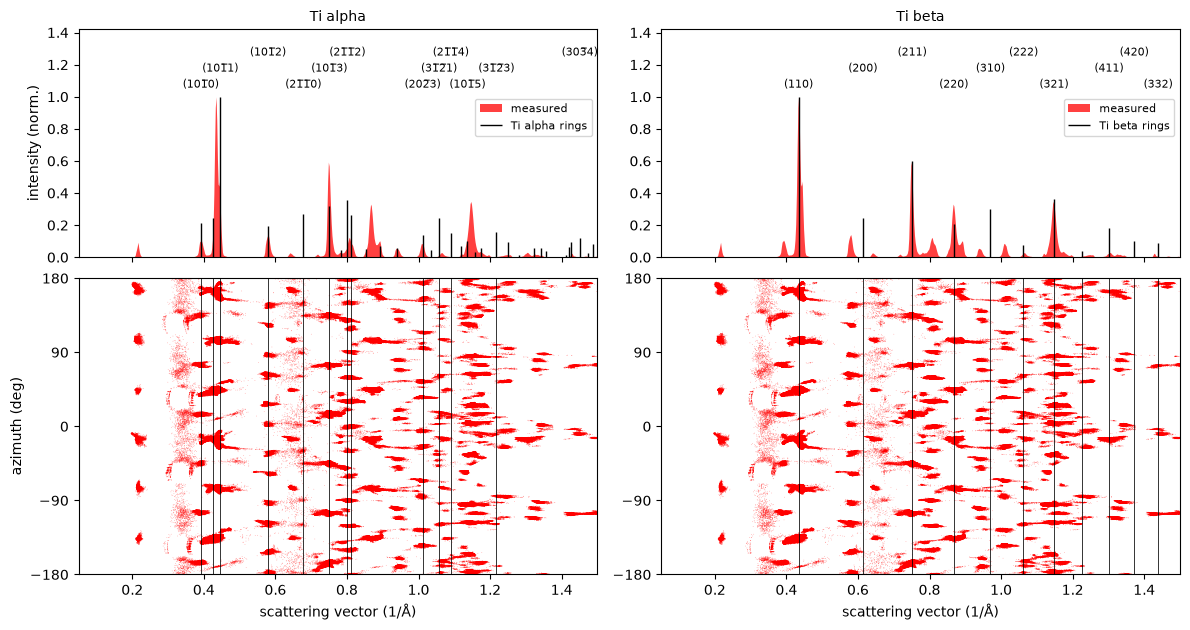

In [12]:
fig, axs = cm.plot_calibration()

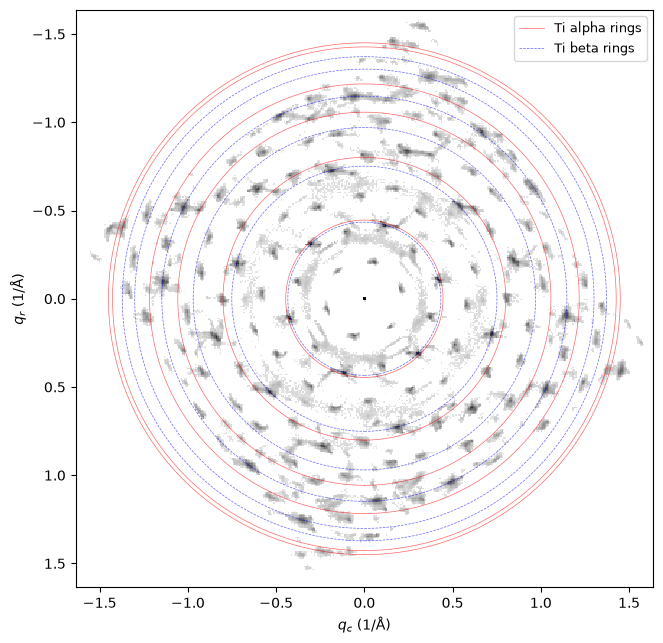

In [13]:
fig, ax = cm.plot_bragg_rings(n_rings=6)

# Check the match before running the scan

`positions` matches only the listed probe positions. The best candidate of each phase is drawn over the measured peaks.

In [14]:
cm.match_orientations(positions=test_positions, **match_params)

matching Ti alpha:   0%|          | 0/1 [00:00<?, ?it/s]

matching Ti alpha: 100%|██████████| 1/1 [00:00<00:00,  5.53it/s]

matching Ti alpha: 100%|██████████| 1/1 [00:00<00:00,  5.52it/s]

matching Ti beta:   0%|          | 0/1 [00:00<?, ?it/s]

matching Ti beta: 100%|██████████| 1/1 [00:00<00:00, 23.50it/s]

CrystalMap(100 x 191, matched, [Ti alpha, Ti beta])

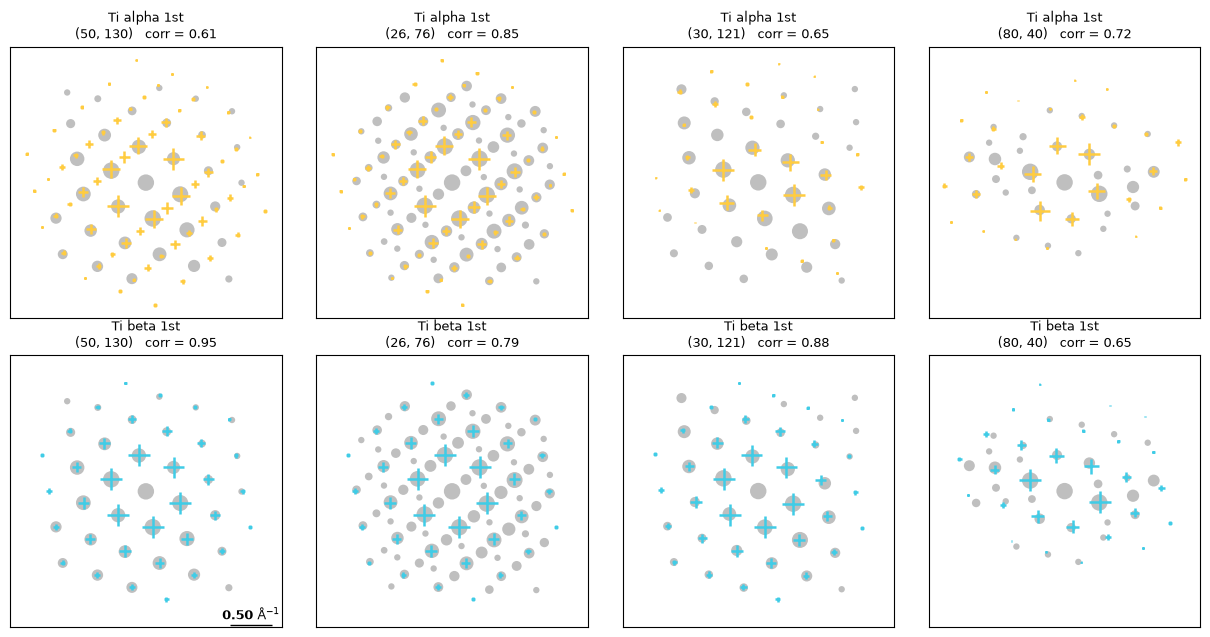

In [15]:
fig, axs = cm.plot_matches(
    positions=test_positions,
    matches=(0,),
    transpose_plots=True,
)

# Run the scan

The same calls without `positions`, then the phase decision. A couple of minutes.

In [16]:
cm.match_orientations(**match_params)
cm.refine_orientations(**refine_params)
cm.fit()

print(cm)
print({k: round(v, 3) for k, v in cm.phase_fractions().items()})

matching Ti alpha:   0%|          | 0/150 [00:00<?, ?it/s]

matching Ti alpha:   1%|          | 1/150 [00:00<00:51,  2.90it/s]

matching Ti alpha:   1%|▏         | 2/150 [00:00<00:42,  3.52it/s]

matching Ti alpha:   2%|▏         | 3/150 [00:00<00:38,  3.80it/s]

matching Ti alpha:   3%|▎         | 4/150 [00:01<00:37,  3.91it/s]

...

phase mapping:  99%|█████████▉| 18913/19096 [00:28<00:00, 642.55it/s]

phase mapping:  99%|█████████▉| 18979/19096 [00:29<00:00, 647.04it/s]

phase mapping: 100%|█████████▉| 19044/19096 [00:29<00:00, 631.96it/s]

phase mapping: 100%|██████████| 19096/19096 [00:29<00:00, 652.19it/s]

CrystalMap(100 x 191, refined, phase fit, [Ti alpha, Ti beta])
{'unindexed': 0.005, 'Ti alpha': 0.487, 'Ti beta': 0.507}


# Phase map

Color gives the crystal, brightness the diffracted signal.

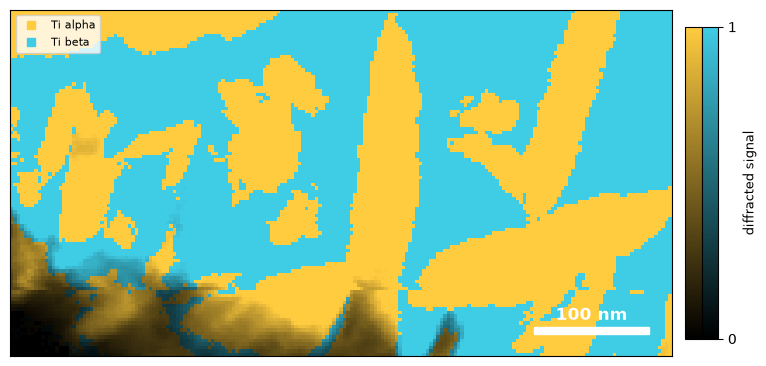

In [17]:
fig, ax = cm.plot_phase()

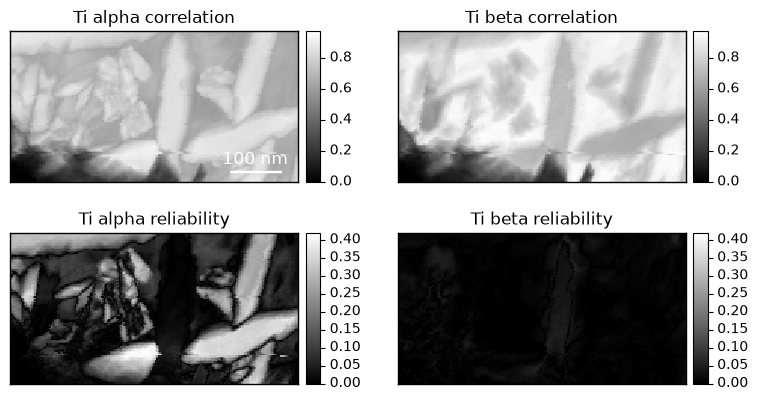

In [18]:
fig, axs = cm.plot_correlation(mask=True)

# Orientation maps

Out-of-plane and in-plane inverse pole figures of each phase, masked by the phase decision. `smooth` averages neighbouring orientations for display only; the stored orientations stay at their fit.

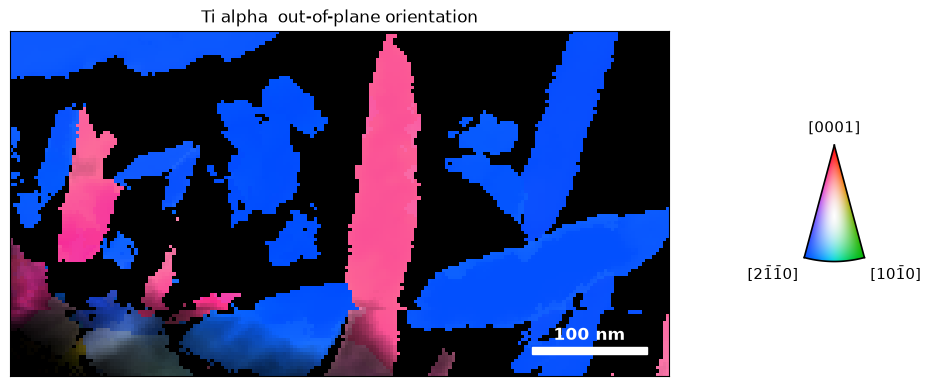

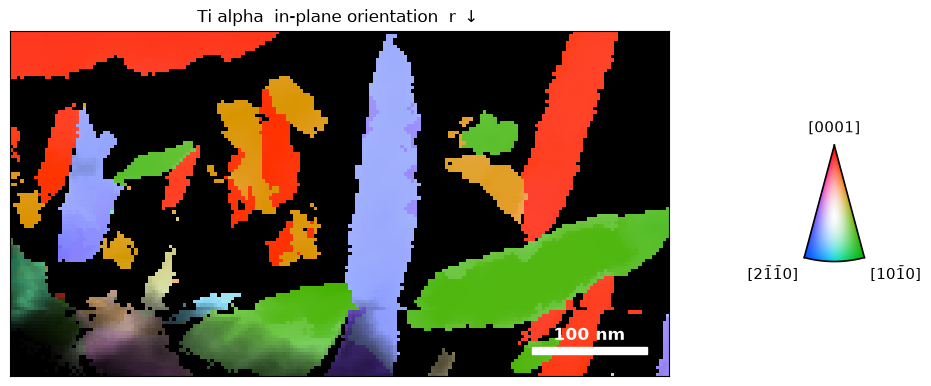

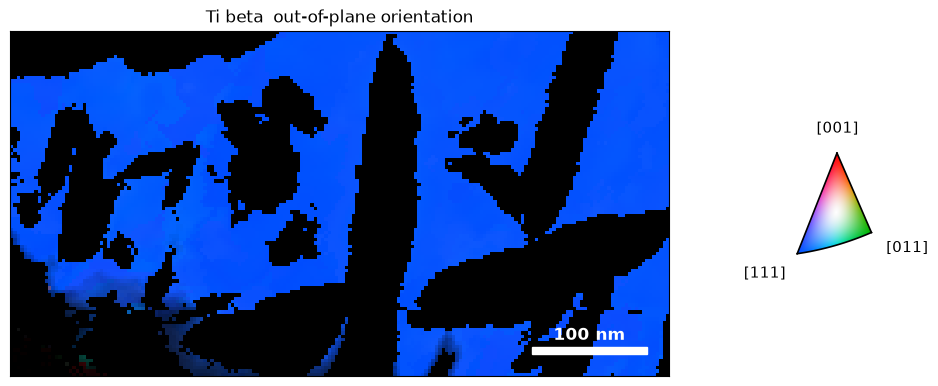

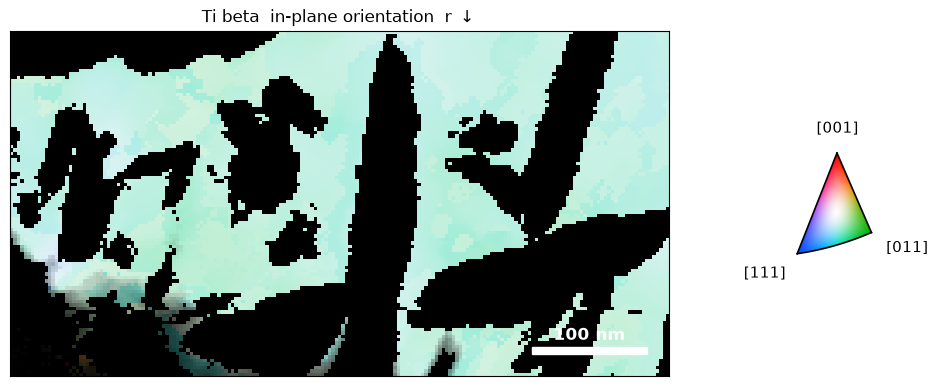

In [19]:
smooth_params = dict(                 # display only
    sigma_px=1.0,                     # spatial width, probe positions
    sigma_deg=1.0,                    # angular width
    max_angle_deg=5.0,                # neighbours beyond this are excluded
)

figs = cm.plot_orientation(smooth=smooth_params)

# Pole figures

The alpha basal poles fall on the <110> poles of the beta matrix, the Burgers orientation relationship (110)beta parallel to (0001)alpha. The beta matrix indexes as two orientations 60 degrees apart about <111>, which are kinematically indistinguishable near a <111> zone; alpha poles that miss the contours belong to the other beta variant.

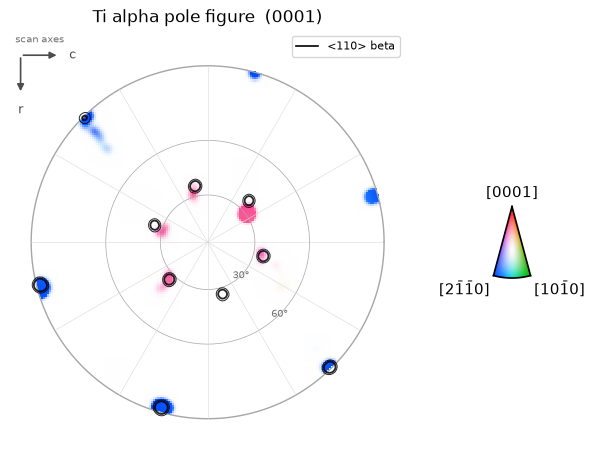

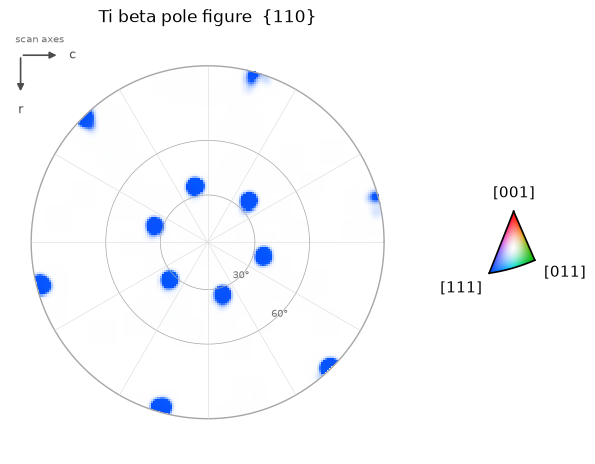

In [20]:
fig, ax = cm.plot_pole_figure(
    pole=(0, 0, 1),
    phase='Ti alpha',
    color_by='ipf',
    int_range=(0.0, 0.2),
    label='(0001)',
    overlay={
        'om': cm['Ti beta'],
        'pole': (1, 1, 0),
        'mask': cm.mask('Ti beta'),
        'label': '<110> beta',
    },
)
fig, ax = cm.plot_pole_figure(
    pole=(1, 1, 0),
    phase='Ti beta',
    color_by='ipf',
    int_range=(0.0, 0.2),
    label='{110}',
)

# Projected strain

At each position the refined simulation is paired with the measured peaks, and the in-plane deformation is solved by least squares. The reference is the ideal lattice of each phase, so no strain-free region is needed.

In [21]:
strain_maps = {
    name: cm[name].calculate_strain(
        mask=cm.mask(name) > 0.5,
        ds_sampling=scan_step,
        ds_units='A',
        progress_bar=False,
    )
    for name in ('Ti alpha', 'Ti beta')
}

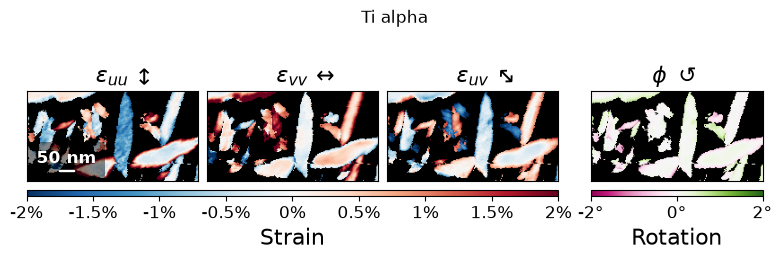

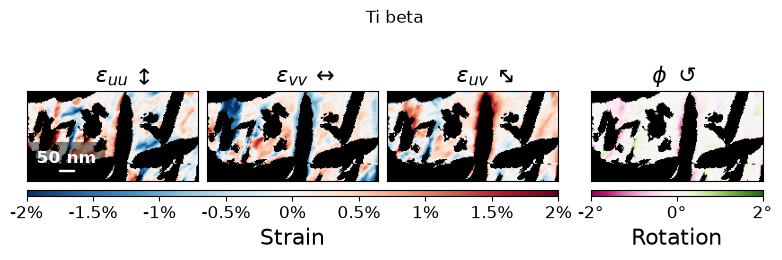

In [22]:
for name, sm in strain_maps.items():
    fig, ax = sm.plot_strain(
        rotation_angle=0.0,              # strain axes along the image rows and columns
        strain_range_percent=(-2.0, 2.0),
        plot_scalebar=True,
    )
    fig.suptitle(name)

# Individual fits

Well separated positions: the clearest alpha, the clearest beta, and the closest calls, over the recorded patterns.

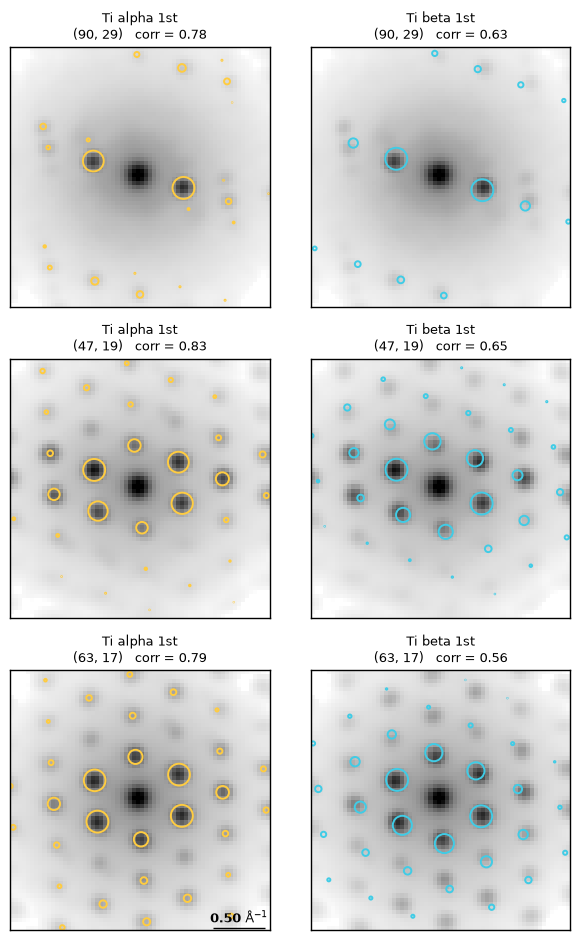

In [23]:
positions = cm.example_positions(phase='Ti alpha', num=3)
fig, axs = cm.plot_matches(
    positions=positions,
    dataset=dataset,
    matches=(0,),
)

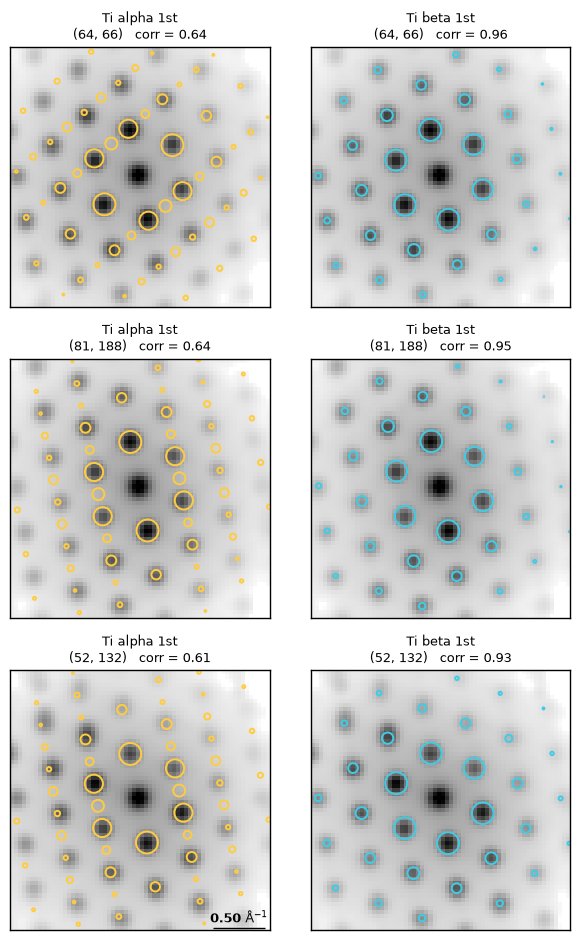

In [24]:
positions = cm.example_positions(phase='Ti beta', num=3)
fig, axs = cm.plot_matches(
    positions=positions,
    dataset=dataset,
    matches=(0,),
)

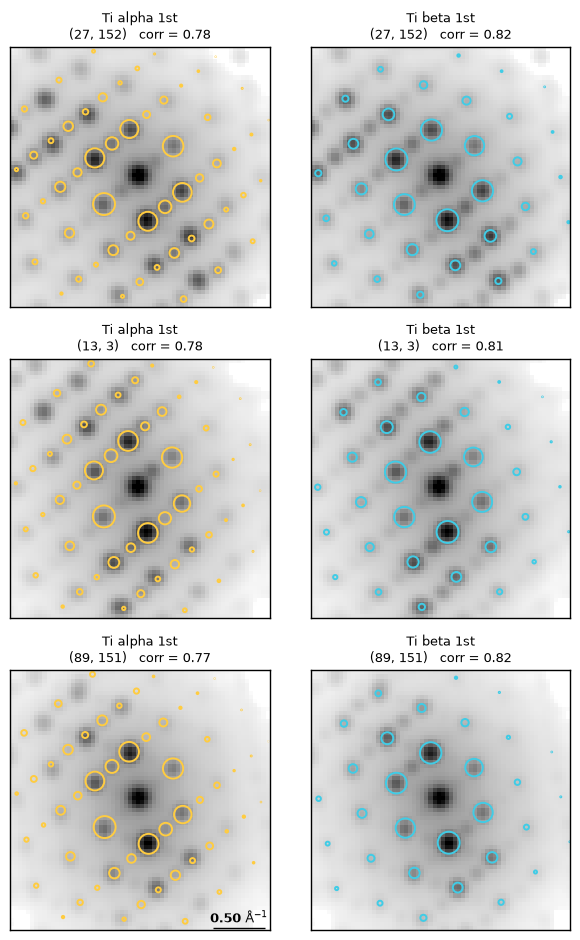

In [25]:
positions = cm.example_positions(ambiguous=True, num=3)
fig, axs = cm.plot_matches(
    positions=positions,
    dataset=dataset,
    matches=(0,),
)

# Save

The `CrystalMap` holds the peaks, orientations and phase decision of the whole analysis.

In [26]:
cm.save('Ti_crystal_map.zip', mode='o')